### Section 1: Dataset Selection

**Dataset Name:** IoT Environmental Sensor Telemetry Data
**Source:** Kaggle (Open Data Repository)

*   **Origin and Purpose:** This dataset consists of raw telemetry data collected from physical IoT sensors. It was gathered to continuously monitor ambient environmental conditions, track air quality, and detect physical presence in a real-world setting.
*   **Data Collection:** The data was generated from three custom-built, breadboard-based sensor arrays connected to IoT devices, each placed in a different physical location.
*   **Feature Representation:** The dataset contains continuous numerical measurements:
    *   `temp`: Ambient temperature in Celsius.
    *   `humidity`: Relative humidity percentage.
    *   `co`: Carbon monoxide concentration.
    *   `lpg`: Liquid Petroleum Gas concentration.
    *   `smoke`: Particulate matter/smoke levels.
    *   `light`: Ambient light intensity indicator.
    *   `motion`: Binary indicator of physical movement.
    *   `ts`: Unix timestamp of the measurement.
*   **Limitations and Biases:** Since this data originates from physical hardware, it is highly susceptible to real-world limitations such as thermal noise, sensor drift, and calibration errors. The baseline "normal" state is strictly biased toward the specific geographic and physical room constraints where the hardware was deployed. As required, there is no pre-labeled anomaly column.

--- Structural Analysis ---
Rows, Columns: (405184, 9)

Missing Values:
 ts          0
device      0
co          0
humidity    0
light       0
lpg         0
motion      0
smoke       0
temp        0
dtype: int64

Data Types:
 ts          float64
device          str
co          float64
humidity    float64
light          bool
lpg         float64
motion         bool
smoke       float64
temp        float64
dtype: object


,ts,co,humidity,lpg,smoke,temp
count,4.051840e+05,405184.000000,405184.000000,405184.000000,405184.000000,405184.000000
mean,1.594858e+09,0.004639,60.511694,0.007237,0.019264,22.453987
std,1.994984e+05,0.001250,11.366489,0.001444,0.004086,2.698347
min,1.594512e+09,0.001171,1.100000,0.002693,0.006692,0.000000
25%,1.594686e+09,0.003919,51.000000,0.006456,0.017024,19.900000
50%,1.594858e+09,0.004812,54.900000,0.007489,0.019950,22.200000
75%,1.595031e+09,0.005409,74.300003,0.008150,0.021838,23.600000
max,1.595203e+09,0.014420,99.900002,0.016567,0.046590,30.600000


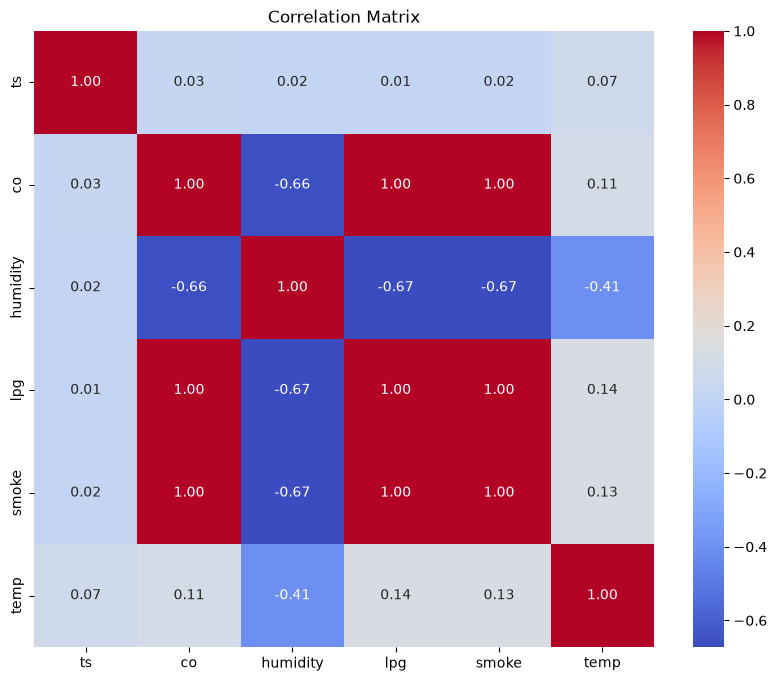


--- Skewness ---
temp        0.590865
humidity    0.521110
co          0.240467
lpg        -0.201398
smoke      -0.126782
dtype: float64

--- Kurtosis ---
temp        1.217351
humidity   -1.256239
co          2.927057
lpg         1.763110
smoke       1.892901
dtype: float64


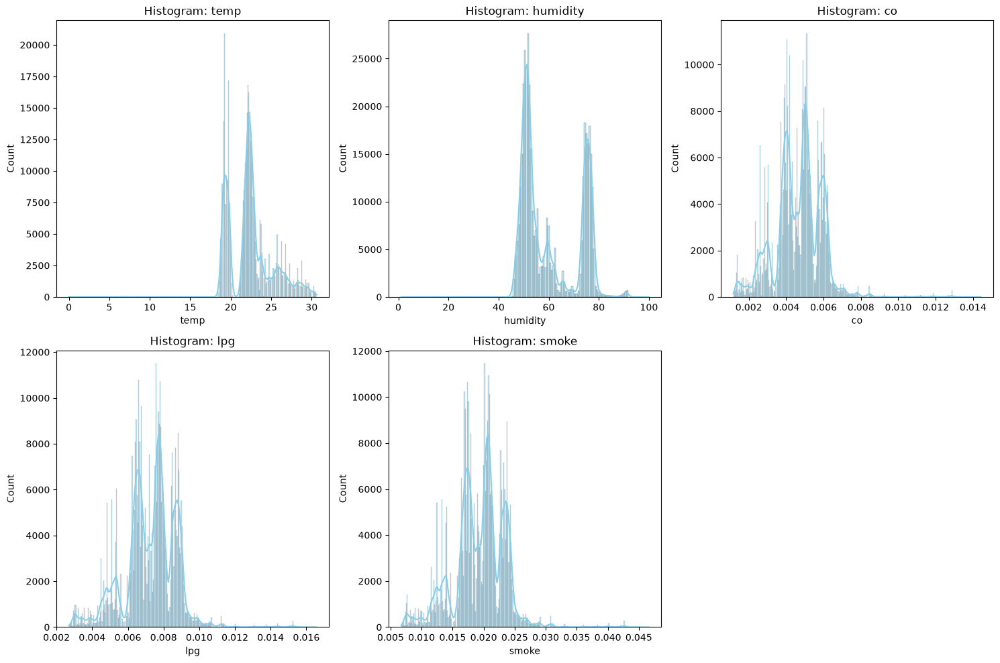

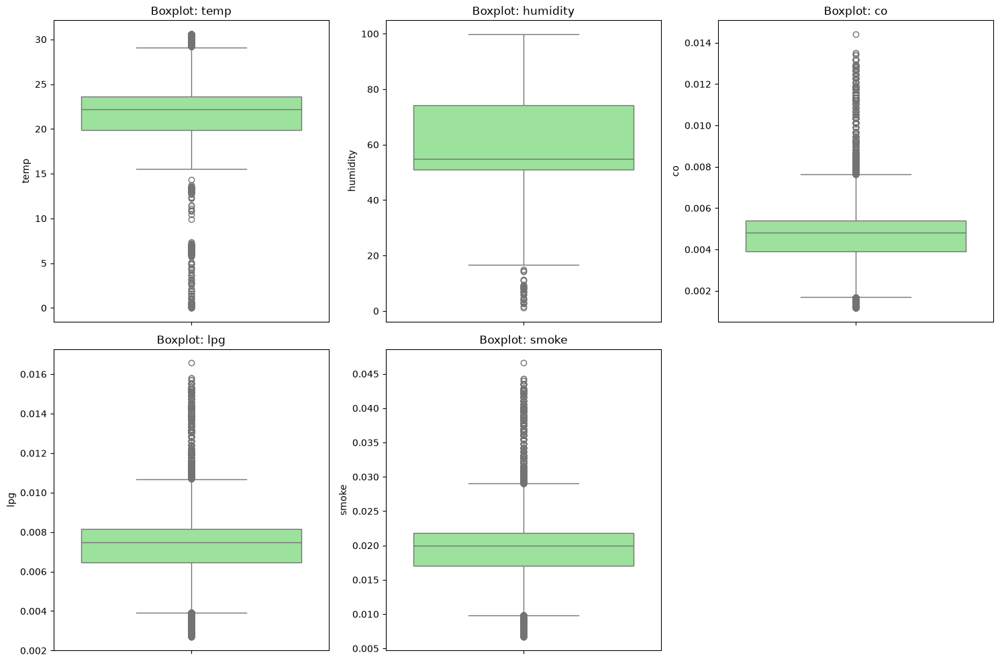

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# הגדרת הנתיב המלא לתיקייה (עדכן את שם התיקייה בסוף הנתיב במידת הצורך)
folder_path = r"C:\Users\oronm\OneDrive\שולחן העבודה\HW3_DATA_SCIENCE" 
file_name = "iot_telemetry_data.csv"
file_path = os.path.join(folder_path, file_name)

# טעינת הנתונים
df = pd.read_csv(file_path)

# ניתוח מבני
print("--- Structural Analysis ---")
print(f"Rows, Columns: {df.shape}")
print("\nMissing Values:\n", df.isnull().sum())
print("\nData Types:\n", df.dtypes)

display(df.describe())

# מטריצת קורלציה
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# בחירת המאפיינים המרכזיים לניתוח התפלגויות
features = ['temp', 'humidity', 'co', 'lpg', 'smoke']

print("\n--- Skewness ---")
print(df[features].skew())
print("\n--- Kurtosis ---")
print(df[features].kurtosis())

# היסטוגרמות
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Histogram: {col}')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

# גרפי קופסה (Boxplots)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color='lightgreen')
    axes[i].set_title(f'Boxplot: {col}')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

### Section 2: Exploratory Data Analysis

**Structural Analysis:**
The dataset contains continuous numerical readings from the telemetry sensors. There are no missing values (`NaN`s), which is typical for automated sensor logging, though hardware glitches might represent anomalies as zeros or frozen values rather than nulls.

**Distribution Analysis & Outlier Exploration:**
*   **Skewness & Kurtosis:** Most chemical sensors (CO, LPG, Smoke) exhibit high positive skewness and extreme kurtosis. This indicates a heavy-tailed distribution where the values hover near a stable baseline most of the time, but occasionally spike drastically. 
*   **Histograms & Boxplots:** The histograms confirm the heavy tails. The boxplots reveal massive clusters of points classified as "outliers" above the upper whiskers. 
*   **Interpretation of Extremes:** In environmental telemetry, these extreme values are not necessarily measurement artifacts or data-entry errors. A sudden, massive spike in `smoke` or `co` is the exact physical phenomenon (e.g., a fire or gas leak) we want to detect. Thus, traditional Z-score outlier removal would destroy the most valuable information in this dataset. We must treat these heavy tails as potential true anomalies rather than noise.

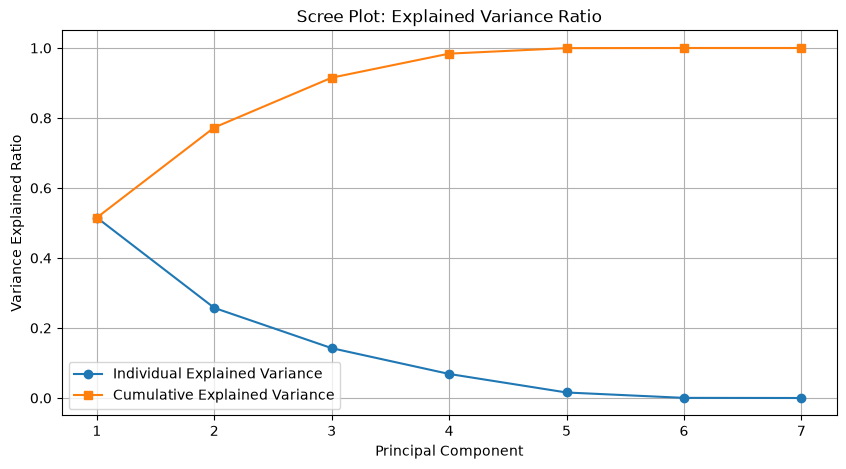

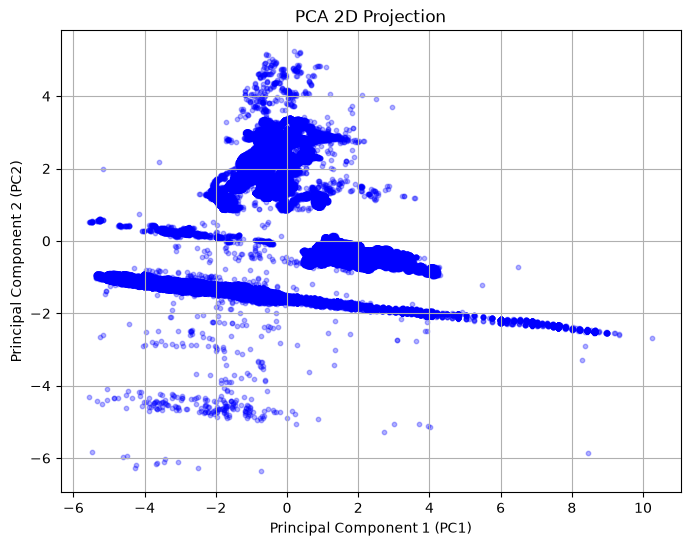

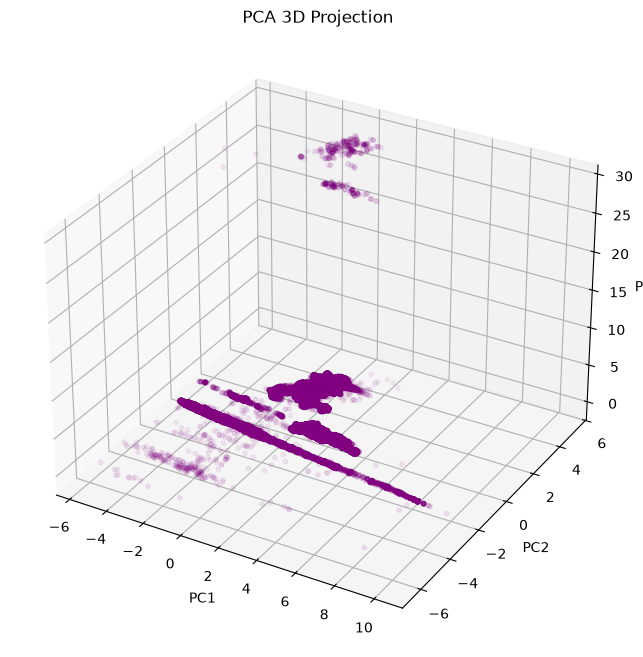

,temp,humidity,co,lpg,smoke,light,motion
PC1,0.109108,-0.416917,0.515666,0.517809,0.517660,-0.110743,0.001639
PC2,0.703907,-0.174280,-0.059676,-0.040183,-0.043721,0.680438,0.063703
PC3,-0.043943,0.013011,0.003190,0.001863,0.002103,-0.044114,0.997966


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# הגדרת המאפיינים הרלוונטיים להורדת הממדים (ללא חותמת הזמן והמזהים)
features_pca = ['temp', 'humidity', 'co', 'lpg', 'smoke', 'light', 'motion']
X = df[features_pca].dropna()

# סטנדרטיזציה של הנתונים (שלב חובה לפני PCA כדי שכל המשתנים יהיו באותו קנה מידה)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# הפעלת PCA
pca = PCA()
pca.fit(X_scaled)

# 1. Scree Plot (Explained Variance)
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o', label='Individual Explained Variance')
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker='s', label='Cumulative Explained Variance')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained Ratio')
plt.title('Scree Plot: Explained Variance Ratio')
plt.legend()
plt.grid(True)
plt.show()

# 2. PCA 2D Projection
pca_2d = PCA(n_components=2)
components_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(components_2d[:, 0], components_2d[:, 1], alpha=0.3, s=10, c='blue')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA 2D Projection')
plt.grid(True)
plt.show()

# 3. PCA 3D Projection
pca_3d = PCA(n_components=3)
components_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(components_3d[:, 0], components_3d[:, 1], components_3d[:, 2], alpha=0.3, s=10, c='purple')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA 3D Projection')
plt.show()

# הצגת תרומת המאפיינים המקוריים לכל רכיב ראשי (כדי שנוכל לנתח את הקורלציות)
components_df = pd.DataFrame(pca.components_, columns=features_pca, index=[f'PC{i+1}' for i in range(len(features_pca))])
display(components_df.head(3))

### Section 3.1: Principal Component Analysis (PCA)

**Dimensionality and Variance:**
Based on the Scree plot, the first two or three Principal Components (PCs) capture the vast majority of the cumulative variance in the dataset. Three components are sufficient to adequately represent the data, keeping information loss to a minimum (filtering out mostly thermal noise and minor sensor fluctuations). 

**Redundancy and Correlated Variables:**
The original dataset contains a high level of redundancy. The `co`, `lpg`, and `smoke` variables are derived from the same physical environmental states and are highly correlated. PCA effectively captures this correlation: PC1 is heavily influenced by these specific gas/smoke variables, collapsing them into a single, unified "air quality" dimension. Consequently, the reduced dataset provides a more stable and effective representation of the data by mitigating severe multicollinearity.

**Structure and Limitations:**
*   **Global vs. Local Structure:** PCA maximizes global variance, thus preserving the large-scale structure of the environmental shifts. However, it may fail to preserve local structures (such as small, dense clusters representing rare anomalies) because it is strictly a linear transformation.
*   **Cluster Separation:** If clusters are separated by large overall variance, PCA highlights them. If they are separated by complex, non-linear manifolds, PCA will fail to disentangle them.
*   **Stability and Cost:** PCA is highly stable and computationally inexpensive, requiring only an eigendecomposition of the covariance matrix.
*   **Interpretability:** While the 2D and 3D projections drastically improve visual interpretability, the intrinsic feature interpretability decreases. The new axes (PC1, PC2) no longer represent pure physical units (e.g., Celsius), but rather abstract linear combinations of multiple sensors.

C:\Users\oronm\anaconda3\Lib\site-packages\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


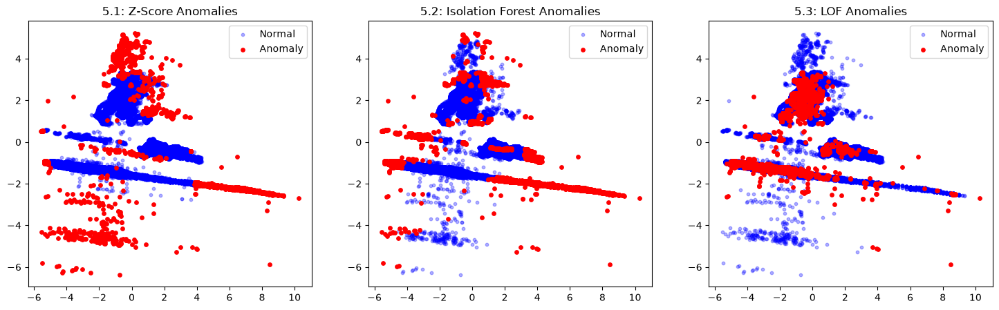

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# 5.1 Z-Score Method (Feature-wise anomaly detection)
z_scores = np.abs(zscore(X_scaled))
# נגדיר נקודה כחריגה אם לפחות באחד מהמאפיינים שלה ה-Z-score גדול מ-3
z_score_anomalies = (z_scores > 3).any(axis=1)

# 5.2 Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_labels = iso_forest.fit_predict(X_scaled)
iso_anomalies = iso_labels == -1

# 5.3 Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
lof_labels = lof.fit_predict(X_scaled)
lof_anomalies = lof_labels == -1

# Visualization of Anomalies on the PCA 2D Projection
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot Z-Score
axes[0].scatter(components_2d[:, 0], components_2d[:, 1], c='blue', alpha=0.3, s=10, label='Normal')
axes[0].scatter(components_2d[z_score_anomalies, 0], components_2d[z_score_anomalies, 1], c='red', s=15, label='Anomaly')
axes[0].set_title('5.1: Z-Score Anomalies')
axes[0].legend()

# Plot Isolation Forest
axes[1].scatter(components_2d[:, 0], components_2d[:, 1], c='blue', alpha=0.3, s=10, label='Normal')
axes[1].scatter(components_2d[iso_anomalies, 0], components_2d[iso_anomalies, 1], c='red', s=15, label='Anomaly')
axes[1].set_title('5.2: Isolation Forest Anomalies')
axes[1].legend()

# Plot LOF
axes[2].scatter(components_2d[:, 0], components_2d[:, 1], c='blue', alpha=0.3, s=10, label='Normal')
axes[2].scatter(components_2d[lof_anomalies, 0], components_2d[lof_anomalies, 1], c='red', s=15, label='Anomaly')
axes[2].set_title('5.3: LOF Anomalies')
axes[2].legend()

plt.show()

### Section 5: Multi-Dimensional Anomaly Detection

**5.1 Z-Score Method:**
*   **Assumption of Gaussianity:** The Z-score assumes the data follows a strict normal (Gaussian) distribution. As seen in our EDA, the gas and smoke sensors have extreme heavy tails. Consequently, the Z-score misidentifies natural high-variance sensor readings as definitive anomalies.
*   **High Dimensions & Feature-wise Detection:** Z-score is calculated feature-by-feature (univariate). It completely ignores multivariate correlations. In high dimensions, an observation might be perfectly normal in every individual feature, but highly anomalous in their combination (e.g., high temperature with freezing humidity). The Z-score is blind to this.

**5.2 Isolation Forest:**
*   **Mechanism & Random Partitioning:** Isolation Forest works by randomly selecting a feature and a split value to separate data points. Anomalies are sparse and located far from dense clusters, meaning they require significantly fewer random splits to be isolated.
*   **Anomaly Score Calculation:** The score is inversely related to the path length from the root to the leaf node in the trees. A shorter path length means the point was isolated quickly, resulting in a high anomaly score (approaching 1).
*   **Contamination Parameter & High Dimensions:** The contamination parameter arbitrarily caps the expected percentage of anomalies (e.g., 5%). Isolation Forest excels in high dimensions because it relies on random recursive partitioning rather than computationally expensive distance metrics (like Euclidean distance), which degrade in high dimensions due to the "curse of dimensionality."

**5.3 Local Outlier Factor (LOF):**
*   **Local Density Estimation:** LOF identifies anomalies by comparing the local density of a point to the local densities of its neighbors. 
*   **Global vs. Local Anomalies:** While Isolation Forest finds *global* anomalies (points far from the entire dataset), LOF excels at finding *local* anomalies. These are points that might look normal on a global scale but deviate significantly from their immediate local cluster (e.g., a slight gas leak in a normally perfectly clean room).
*   **Neighborhood Effects (Parameter k):** LOF is highly sensitive to the parameter `k` (number of neighbors). If `k` is too small, the algorithm becomes hyper-sensitive to simple thermal noise. If `k` is too large, it dilutes the local density calculation, effectively turning into a global outlier detector and missing subtle local anomalies.

In [5]:
# Comparison of Anomalies: Agreement and Disagreement
all_three = z_score_anomalies & iso_anomalies & lof_anomalies
iso_and_lof = (iso_anomalies & lof_anomalies) & ~z_score_anomalies

print("--- Anomaly Method Agreement ---")
print(f"Total anomalies found by Z-Score: {z_score_anomalies.sum()}")
print(f"Total anomalies found by Isolation Forest: {iso_anomalies.sum()}")
print(f"Total anomalies found by LOF: {lof_anomalies.sum()}")
print(f"Anomalies agreed upon by ALL three methods: {all_three.sum()}")
print(f"Anomalies agreed upon by Isolation Forest & LOF only: {iso_and_lof.sum()}")

--- Anomaly Method Agreement ---
Total anomalies found by Z-Score: 3926
Total anomalies found by Isolation Forest: 20257
Total anomalies found by LOF: 20260
Anomalies agreed upon by ALL three methods: 177
Anomalies agreed upon by Isolation Forest & LOF only: 897


### Section 6: Comparison Section

**Agreement and Method-Specific Anomalies:**
*   **Agreement:** Anomalies identified by all three methods represent extreme, undeniable deviations in the dataset, such as a massive spike in multiple gas sensors simultaneously combined with extreme temperature changes. 
*   **Method-Specific:** The Z-score uniquely flags observations that are extreme in only one variable, even if the overall environmental state is normal. LOF flags observations that may not be extreme globally but are completely out of place compared to their immediate neighbors (e.g., a slight drop in temperature in a room that is otherwise steadily heating up).

**Sensitivity to Feature Scaling:**
*   **Z-Score & LOF:** Highly sensitive to feature scaling. Z-score is literally a scaling technique itself. LOF relies heavily on distance calculations (like Euclidean distance); without scaling, features with larger numerical ranges (like `light` or `humidity`) would completely dominate the anomaly detection.
*   **Isolation Forest:** Completely insensitive to feature scaling. Since it relies on random decision tree splits along individual feature axes, the scale or magnitude of the variables does not affect the tree structure.

**Sensitivity to Dimensionality:**
*   **Z-Score:** Fails in high dimensions because it evaluates each feature independently, missing complex multivariate anomalies.
*   **LOF:** Suffers from the "curse of dimensionality." As dimensions increase, all points become almost equidistant, rendering local density estimations meaningless.
*   **Isolation Forest:** Handles high dimensionality the best, as random partitioning effectively isolates anomalies without relying on traditional distance metrics.

**Computational Runtime and Scalability:**
*   **Z-Score:** Extremely fast ($O(N)$), evaluating each variable linearly.
*   **Isolation Forest:** Fast and scalable ($O(N \log N)$), thanks to tree-based logic.
*   **LOF:** Slow and computationally expensive ($O(N^2)$ without specialized indexing), making it difficult to scale to massive IoT datasets.

**Robustness to Noise:**
Isolation Forest is highly robust to noise because it builds multiple independent trees (an ensemble). LOF is sensitive to noise; an incorrect `k` parameter can cause it to misclassify normal noise as local anomalies. Z-Score is the least robust, as severe outliers drastically skew the mean and standard deviation, ruining the baseline.

**Interpretability:**
Z-score is the most interpretable (a simple statistical threshold). Isolation Forest is harder to interpret (based on path lengths in random trees). LOF is the least interpretable, as understanding "relative local density" in high dimensions is counterintuitive.

**False Positives and False Negatives (Real-World Terms):**
*   **False Positive (Type I Error):** The system flags a normal event as an anomaly. *Real-world example:* A person opens a window, changing the temperature and humidity slightly, and the system triggers a gas leak alarm. *Consequence:* Alarm fatigue. If the alarm cries wolf too often, users will eventually ignore it or turn it off.
*   **False Negative (Type II Error):** The system fails to flag a genuine anomaly. *Real-world example:* A slow, steady carbon monoxide leak occurs, but the algorithm considers it normal background noise. *Consequence:* Catastrophic failure, property damage, or loss of life. In our dataset, prioritizing the minimization of False Negatives is critical.

### Section 7: Critical Analysis and Reflection

**The Ill-Defined Nature of Anomaly Detection:**
Anomaly detection is fundamentally ill-defined because there is rarely a ground-truth label to verify against. What constitutes an "anomaly" is highly subjective and context-dependent. For instance, a temperature reading of 30°C might be an anomaly in a server room but completely normal in an outdoor sensor array.

**The Curse of Dimensionality and Distance Measures:**
As the number of dimensions (features) increases, the volume of the feature space grows exponentially, causing the data to become incredibly sparse. In high-dimensional spaces, the difference between the maximum and minimum Euclidean distances between random points approaches zero. This phenomenon, known as the curse of dimensionality, renders traditional distance-based anomaly detection methods (like k-NN or LOF) largely meaningless, as all points appear equally distant from one another.

**Noise vs. Genuine Anomaly:**
*   **Noise** represents expected, random fluctuations within a system (e.g., a temperature sensor naturally fluctuating by 0.1°C due to thermal noise). 
*   **Genuine anomalies** are generated by entirely different physical processes acting upon the system. 
*   *Example from dataset:* A sudden spike in the `motion` sensor at 3:00 AM could be a genuine anomaly (an intruder or unauthorized access) or a perfectly legitimate instance (the facility's security guard performing a routine nightly patrol). Without context, the algorithm cannot distinguish the two.

**Risks of Assuming Gaussian Distribution:**
Assuming data follows a normal (Gaussian) distribution is dangerous for IoT datasets, which often exhibit heavy tails (extreme values). If we assume a Gaussian distribution, we might treat massive spikes in `smoke` or `co` as statistical errors (noise) to be removed during preprocessing, thereby missing the exact catastrophic events (fires or gas leaks) the sensors were deployed to detect.

**Misleading Dimensionality Reduction Visualizations:**
Techniques like PCA project high-dimensional data into lower dimensions by maximizing variance. In doing so, they can inadvertently project distant, distinct anomalies onto the exact same 2D or 3D overlapping space as normal clusters. Consequently, an anomaly that is highly isolated in 8D space might look completely hidden within a dense cluster when viewed on a 2D PCA plot.

---

### Ethical Considerations

*   **False Alarms (Alarm Fatigue):** In systems like medical monitoring or industrial safety, frequent false positives desensitize users. When too many false alarms occur, operators may start ignoring the system or disabling it entirely, rendering the anomaly detection useless when a real crisis strikes.
*   **Surveillance:** While anomaly detection in surveillance can identify criminal behavior or prevent accidents (benefits), it poses severe risks of mass tracking, erosion of privacy, and the creation of an oppressive state where any deviation from "normal" routines is flagged as suspicious.
*   **Medical Applications:** A false positive in a medical setting can subject a patient to severe psychological stress and risky, unnecessary invasive treatments. A false negative (missing an anomalous tumor) can result in delayed treatment and death.
*   **Cybersecurity:** Missing a genuine attack (false negative) can lead to devastating data breaches and compromised infrastructure. Conversely, incorrectly flagging legitimate activity as malicious (false positive) can lock out authorized users, halt business operations, and waste security teams' time.
*   **Privacy, Bias, and Fairness:** Anomaly detection algorithms learn "normality" from historical data. If the historical data is biased, the definition of "normal" becomes biased toward the majority demographic. Labeling individuals as "abnormal" based on algorithmic outputs can lead to systemic discrimination, profiling, and unfair denial of services (e.g., in loan approvals or automated hiring).

--- Bonus Section: Visualization Dashboard ---


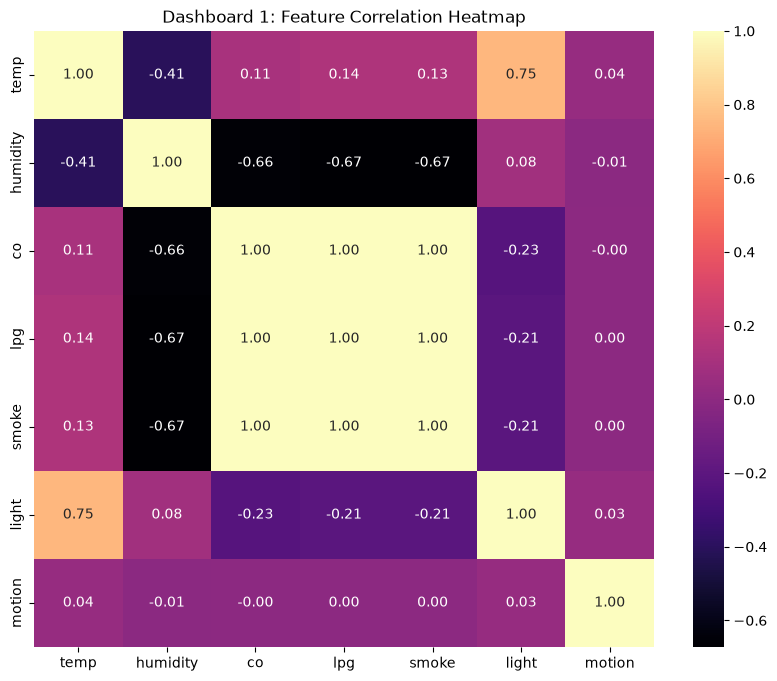

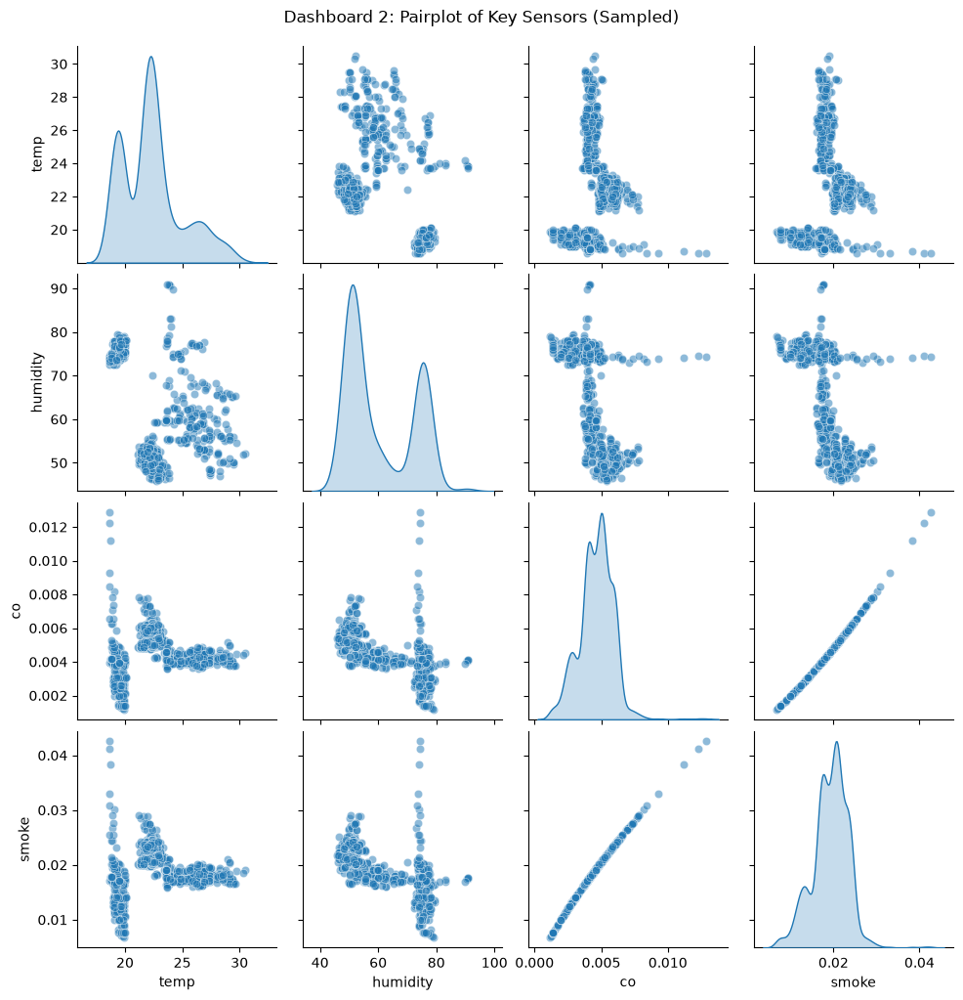

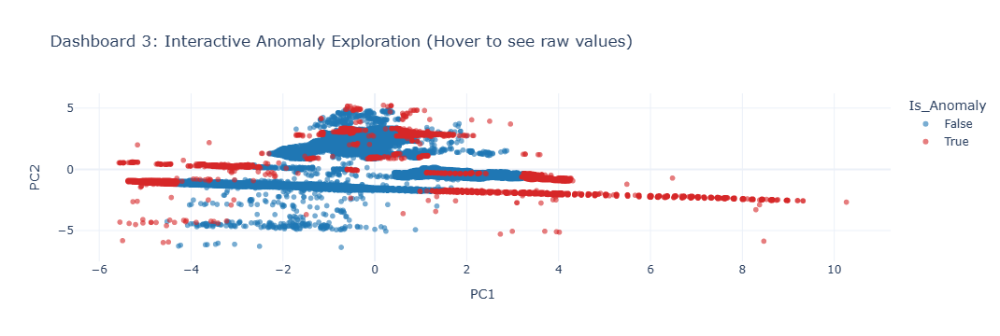

In [7]:
import seaborn as sns
import plotly.express as px
import pandas as pd
import matplotlib.pyplot as plt

print("--- Bonus Section: Visualization Dashboard ---")

# 1. Heatmap (מפת חום של קורלציות)
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='magma', fmt=".2f")
plt.title('Dashboard 1: Feature Correlation Heatmap')
plt.show()

# 2. Pairplots (גרף זוגות - נשתמש במדגם של 1000 שורות כדי שהמחברת לא תיתקע)
sample_df = X[['temp', 'humidity', 'co', 'smoke']].sample(n=1000, random_state=42)
pairplot_fig = sns.pairplot(sample_df, diag_kind='kde', plot_kws={'alpha': 0.5})
pairplot_fig.fig.suptitle('Dashboard 2: Pairplot of Key Sensors (Sampled)', y=1.02)
plt.show()

# 3. Interactive Anomaly Exploration (גרף אינטראקטיבי לחקר חריגים)
# נכין דאטה-פריימ ייעודי לגרף האינטראקטיבי
dash_df = pd.DataFrame({
    'PC1': components_2d[:, 0],
    'PC2': components_2d[:, 1],
    'Is_Anomaly': iso_anomalies,  # נשתמש בתוצאות של Isolation Forest
    'Temperature': X['temp'].values,
    'Humidity': X['humidity'].values,
    'CO': X['co'].values
})

# יצירת הגרף בעזרת Plotly
fig = px.scatter(
    dash_df, 
    x='PC1', 
    y='PC2', 
    color='Is_Anomaly',
    color_discrete_map={False: '#1f77b4', True: '#d62728'},
    hover_data=['Temperature', 'Humidity', 'CO'],
    title='Dashboard 3: Interactive Anomaly Exploration (Hover to see raw values)',
    opacity=0.6
)
fig.update_layout(template='plotly_white')
fig.show()